1. Loading synthetic dataset

In [11]:
from google.colab import drive
drive.mount('/content/drive')

BASE = '/content/drive/MyDrive/mzazicare-ml'
DATA = f'{BASE}/data'
MODELS = f'{BASE}/models'

import os
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

os.makedirs(MODELS, exist_ok=True)

df = pd.read_parquet(f'{DATA}/synthetic_anomaly_dataset.parquet')
print(f"Loaded: {df.shape}")
print(df.columns.tolist())
print(f"\nAnomaly rate: {df['is_anomaly'].mean()*100:.2f}%")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Loaded: (16249, 13)
['User ID', 'login_hour', 'login_day_of_week', 'time_deviation', 'is_known_country', 'is_known_city', 'is_foreign_login', 'location_anomaly_score', 'is_known_device', 'login_velocity', 'anomaly_type', 'severity', 'is_anomaly']

Anomaly rate: 9.09%


2. Separating dataset features and labels

In [12]:
features = [
    'login_hour',
    'login_day_of_week',
    'time_deviation',
    'is_known_country',
    'is_known_city',
    'is_foreign_login',
    'location_anomaly_score',
    'is_known_device',
    'login_velocity',
]

X = df[features].copy()
y = df['is_anomaly'].copy()

# Keeping anomaly_type and severity aside for later analysis
meta = df[['anomaly_type', 'severity']].copy()

print(f"Feature matrix: {X.shape}")
print(f"Labels: {y.shape}")
print(f"\nAnomaly count: {y.sum():,} ({y.mean()*100:.2f}%)")

Feature matrix: (16249, 9)
Labels: (16249,)

Anomaly count: 1,477 (9.09%)


3. Scaling features

In [13]:
print("Feature distributions before scaling:")
print(X.describe().round(4))

print(f"\nlogin_velocity skew: {X['login_velocity'].skew():.2f}")

Feature distributions before scaling:
       login_hour  login_day_of_week  time_deviation  is_known_country  \
count  16249.0000         16249.0000      16249.0000        16249.0000   
mean      11.9165             2.0516          3.2015            0.9708   
std        5.3157             1.8269          2.9454            0.1683   
min        0.0000             0.0000          0.0000            0.0000   
25%        8.0000             0.0000          1.0000            1.0000   
50%       12.0000             2.0000          2.3750            1.0000   
75%       16.0000             3.0000          4.6667            1.0000   
max       24.0000             6.0000         16.4000            1.0000   

       is_known_city  is_foreign_login  location_anomaly_score  \
count     16249.0000        16249.0000              16249.0000   
mean          0.9631            0.0292                  0.0515   
std           0.1886            0.1683                  0.2739   
min           0.0000           

4. Applying log-transform to correct skew of >2

In [14]:
from sklearn.preprocessing import StandardScaler

# Apply log-transform to login_velocity if highly skewed
if X['login_velocity'].max() > 20:
    X['login_velocity'] = np.log1p(X['login_velocity'])
    print("Log-transform applied to login_velocity")

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled = pd.DataFrame(X_scaled, columns=features)

print("Features scaled successfully")
print(X_scaled.describe().round(4))

Log-transform applied to login_velocity
Features scaled successfully
       login_hour  login_day_of_week  time_deviation  is_known_country  \
count  16249.0000         16249.0000      16249.0000        16249.0000   
mean      -0.0000            -0.0000         -0.0000            0.0000   
std        1.0000             1.0000          1.0000            1.0000   
min       -2.2418            -1.1230         -1.0870           -5.7689   
25%       -0.7368            -1.1230         -0.7475            0.1733   
50%        0.0157            -0.0282         -0.2806            0.1733   
75%        0.7682             0.5192          0.4975            0.1733   
max        2.2732             2.1613          4.4812            0.1733   

       is_known_city  is_foreign_login  location_anomaly_score  \
count     16249.0000        16249.0000              16249.0000   
mean         -0.0000           -0.0000                  0.0000   
std           1.0000            1.0000                  1.0000   


5. Splitting the dataset

In [15]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test, meta_train, meta_test = train_test_split(
    X_scaled, y, meta,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(f"Training set: {X_train.shape}")
print(f"Test set:     {X_test.shape}")
print(f"\nAnomalies in training: {y_train.sum():,} ({y_train.mean()*100:.2f}%)")
print(f"Anomalies in test:     {y_test.sum():,} ({y_test.mean()*100:.2f}%)")

Training set: (12999, 9)
Test set:     (3250, 9)

Anomalies in training: 1,182 (9.09%)
Anomalies in test:     295 (9.08%)


6. Setting contamination parameters for training with Isolation Forest

In [16]:
from sklearn.ensemble import IsolationForest
import time

contamination = round(float(y_train.mean()), 4)
print(f"Contamination set to actual anomaly rate: {contamination}")

print("\nTraining Isolation Forest...")
start = time.time()

model = IsolationForest(
    n_estimators=200,
    contamination=contamination,
    max_samples=256,
    max_features=0.8,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

model.fit(X_train)

elapsed = time.time() - start
print(f"\nTraining complete in {elapsed:.1f} seconds")

Contamination set to actual anomaly rate: 0.0909

Training Isolation Forest...


[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.



Training complete in 0.6 seconds


[Parallel(n_jobs=2)]: Done   2 out of   2 | elapsed:    0.5s finished
[Parallel(n_jobs=1)]: Done  49 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 199 tasks      | elapsed:    0.2s
[Parallel(n_jobs=1)]: Done 200 out of 200 | elapsed:    0.2s finished


7. Evaluating predictions and risk scores

In [17]:
y_pred = model.predict(X_test)
y_pred_binary = (y_pred == -1).astype(int)

decision_scores = model.decision_function(X_test)
risk_scores = 1 - (decision_scores - decision_scores.min()) / (
    decision_scores.max() - decision_scores.min()
)
risk_scores_100 = (risk_scores * 100).round(2)

print(f"Predictions generated: {len(y_pred_binary):,}")
print(f"Predicted anomalies: {y_pred_binary.sum():,} ({y_pred_binary.mean()*100:.2f}%)")
print(f"\nRisk score distribution:")
print(pd.Series(risk_scores_100).describe().round(2))

Predictions generated: 3,250
Predicted anomalies: 282 (8.68%)

Risk score distribution:
count    3250.00
mean       16.44
std        17.46
min         0.00
25%         5.72
50%        10.30
75%        20.01
max       100.00
dtype: float64


[Parallel(n_jobs=1)]: Done  49 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 199 tasks      | elapsed:    0.1s
[Parallel(n_jobs=1)]: Done 200 out of 200 | elapsed:    0.1s finished
[Parallel(n_jobs=1)]: Done  49 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 199 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 200 out of 200 | elapsed:    0.0s finished


8. Complete evaluation of model including precision, recall, F1 score, confusion matrix and a classfication report

In [18]:
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)

y_true = y_test.values

precision = precision_score(y_true, y_pred_binary, zero_division=0)
recall = recall_score(y_true, y_pred_binary, zero_division=0)
f1 = f1_score(y_true, y_pred_binary, zero_division=0)
fpr = ((y_pred_binary == 1) & (y_true == 0)).sum() / (y_true == 0).sum()

print("=" * 55)
print("MODEL EVALUATION REPORT — SYNTHETIC ANOMALY DATASET")
print("=" * 55)
print(f"\nPrecision:           {precision:.4f}  (target: > 0.80)")
print(f"Recall:              {recall:.4f}  (target: > 0.85)")
print(f"F1 Score:            {f1:.4f}  (target: > 0.82)")
print(f"False Positive Rate: {fpr:.4f}  (target: < 0.05)")

print("\nTargets met:")
print(f"  Precision > 0.80:  {'PASS' if precision > 0.80 else 'FAIL'}")
print(f"  Recall > 0.85:     {'PASS' if recall > 0.85 else 'FAIL'}")
print(f"  F1 > 0.82:         {'PASS' if f1 > 0.82 else 'FAIL'}")
print(f"  FPR < 0.05:        {'PASS' if fpr < 0.05 else 'FAIL'}")

cm = confusion_matrix(y_true, y_pred_binary)
print(f"\nConfusion Matrix:")
print(f"  True Negatives:  {cm[0][0]:,}")
print(f"  False Positives: {cm[0][1]:,}")
print(f"  False Negatives: {cm[1][0]:,}")
print(f"  True Positives:  {cm[1][1]:,}")

print("\nFull Classification Report:")
print(classification_report(y_true, y_pred_binary, target_names=['Normal', 'Anomaly']))

MODEL EVALUATION REPORT — SYNTHETIC ANOMALY DATASET

Precision:           0.7270  (target: > 0.80)
Recall:              0.6949  (target: > 0.85)
F1 Score:            0.7106  (target: > 0.82)
False Positive Rate: 0.0261  (target: < 0.05)

Targets met:
  Precision > 0.80:  FAIL
  Recall > 0.85:     FAIL
  F1 > 0.82:         FAIL
  FPR < 0.05:        PASS

Confusion Matrix:
  True Negatives:  2,878
  False Positives: 77
  False Negatives: 90
  True Positives:  205

Full Classification Report:
              precision    recall  f1-score   support

      Normal       0.97      0.97      0.97      2955
     Anomaly       0.73      0.69      0.71       295

    accuracy                           0.95      3250
   macro avg       0.85      0.83      0.84      3250
weighted avg       0.95      0.95      0.95      3250



9. Breakdown analysis of anomalies to show which categories the model catches best

In [19]:
results_df = meta_test.copy()
results_df['true_label'] = y_true
results_df['predicted'] = y_pred_binary
results_df['risk_score'] = risk_scores_100

print("Detection rate by anomaly type (anomalies only):")
anomaly_only = results_df[results_df['true_label'] == 1]
type_breakdown = anomaly_only.groupby('anomaly_type').agg(
    count=('predicted', 'count'),
    detected=('predicted', 'sum'),
).reset_index()
type_breakdown['detection_rate'] = (type_breakdown['detected'] / type_breakdown['count'] * 100).round(1)
print(type_breakdown.to_string(index=False))

Detection rate by anomaly type (anomalies only):
anomaly_type  count  detected  detection_rate
    combined     59        59           100.0
      device     57        57           100.0
    location     49        49           100.0
        time     77        19            24.7
    velocity     53        21            39.6


10. Breakdown analysis of anomaly detection by severity

In [20]:
print("Detection rate by severity level (anomalies only):")
severity_breakdown = anomaly_only.groupby('severity').agg(
    count=('predicted', 'count'),
    detected=('predicted', 'sum'),
    avg_risk_score=('risk_score', 'mean'),
).reset_index()
severity_breakdown['detection_rate'] = (severity_breakdown['detected'] / severity_breakdown['count'] * 100).round(1)

# Order severity logically
severity_order = ['mild', 'moderate', 'severe']
severity_breakdown['severity'] = pd.Categorical(severity_breakdown['severity'], categories=severity_order, ordered=True)
severity_breakdown = severity_breakdown.sort_values('severity')

print(severity_breakdown.to_string(index=False))
print("\nExpected pattern: detection_rate and avg_risk_score should increase from mild -> severe.")
print("This demonstrates the model's sensitivity scales with deviation magnitude, not a fixed threshold artifact.")

Detection rate by severity level (anomalies only):
severity  count  detected  avg_risk_score  detection_rate
    mild    163        92       46.120429            56.4
moderate     76        57       59.312368            75.0
  severe     56        56       71.606786           100.0

Expected pattern: detection_rate and avg_risk_score should increase from mild -> severe.
This demonstrates the model's sensitivity scales with deviation magnitude, not a fixed threshold artifact.


11. Training a second model (model_v2) with a lower max_features value for comparison

In [21]:
model_v2 = IsolationForest(
    n_estimators=200,
    contamination=contamination,
    max_samples=256,
    max_features=0.5,   # reduced from 0.8
    random_state=42,
    n_jobs=-1
)
model_v2.fit(X_train)

y_pred_v2 = model_v2.predict(X_test)
y_pred_v2_binary = (y_pred_v2 == -1).astype(int)

precision_v2 = precision_score(y_true, y_pred_v2_binary, zero_division=0)
recall_v2 = recall_score(y_true, y_pred_v2_binary, zero_division=0)
f1_v2 = f1_score(y_true, y_pred_v2_binary, zero_division=0)
fpr_v2 = ((y_pred_v2_binary == 1) & (y_true == 0)).sum() / (y_true == 0).sum()

print("Original (max_features=0.8):")
print(f"  Precision: {precision:.4f} | Recall: {recall:.4f} | F1: {f1:.4f} | FPR: {fpr:.4f}")
print("\nv2 (max_features=0.5):")
print(f"  Precision: {precision_v2:.4f} | Recall: {recall_v2:.4f} | F1: {f1_v2:.4f} | FPR: {fpr_v2:.4f}")

# Deciding which model to keep going forward
use_v2 = f1_v2 > f1
print(f"\n{'v2 performs better — using model_v2 going forward' if use_v2 else 'Original performs better — keeping original model'}")

final_model = model_v2 if use_v2 else model
final_precision, final_recall, final_f1, final_fpr = (
    (precision_v2, recall_v2, f1_v2, fpr_v2) if use_v2 else (precision, recall, f1, fpr)
)

Original (max_features=0.8):
  Precision: 0.7270 | Recall: 0.6949 | F1: 0.7106 | FPR: 0.0261

v2 (max_features=0.5):
  Precision: 0.7545 | Recall: 0.7085 | F1: 0.7308 | FPR: 0.0230

v2 performs better — using model_v2 going forward


12. Training comparison models: One-Class SVM, Local Outlier Factor (LOF), Elliptic Envelope

In [22]:
from sklearn.svm import OneClassSVM
from sklearn.neighbors import LocalOutlierFactor
from sklearn.covariance import EllipticEnvelope

print("Training comparison models...")

# One-Class SVM
ocsvm = OneClassSVM(nu=contamination, kernel='rbf', gamma='scale')
ocsvm.fit(X_train)
print("  One-Class SVM trained")

# Local Outlier Factor (novelty=True allows predict() on new/test data)
lof = LocalOutlierFactor(n_neighbors=20, contamination=contamination, novelty=True)
lof.fit(X_train)
print("  Local Outlier Factor trained")

# Elliptic Envelope
envelope = EllipticEnvelope(contamination=contamination, random_state=42)
envelope.fit(X_train)
print("  Elliptic Envelope trained")

print("\nAll comparison models trained.")

Training comparison models...
  One-Class SVM trained
  Local Outlier Factor trained
  Elliptic Envelope trained

All comparison models trained.


13. Evaluating all models using a shared function

In [23]:
def evaluate_model(name, y_true, predictions_raw):
    """predictions_raw: -1 = anomaly, 1 = normal (standard sklearn outlier convention)"""
    pred_binary = (predictions_raw == -1).astype(int)
    p = precision_score(y_true, pred_binary, zero_division=0)
    r = recall_score(y_true, pred_binary, zero_division=0)
    f = f1_score(y_true, pred_binary, zero_division=0)
    fp_rate = ((pred_binary == 1) & (y_true == 0)).sum() / (y_true == 0).sum()
    return {'model': name, 'precision': p, 'recall': r, 'f1_score': f, 'false_positive_rate': fp_rate}

results = []
results.append(evaluate_model('Isolation Forest', y_true, final_model.predict(X_test)))
results.append(evaluate_model('One-Class SVM', y_true, ocsvm.predict(X_test)))
results.append(evaluate_model('Local Outlier Factor', y_true, lof.predict(X_test)))
results.append(evaluate_model('Elliptic Envelope', y_true, envelope.predict(X_test)))

comparison_results = pd.DataFrame(results)
print(comparison_results.round(4).to_string(index=False))

               model  precision  recall  f1_score  false_positive_rate
    Isolation Forest     0.7545  0.7085    0.7308               0.0230
       One-Class SVM     0.7040  0.6610    0.6818               0.0277
Local Outlier Factor     0.1743  0.1797    0.1770               0.0849
   Elliptic Envelope     0.8211  0.7932    0.8069               0.0173


14. Visualizing the comparison

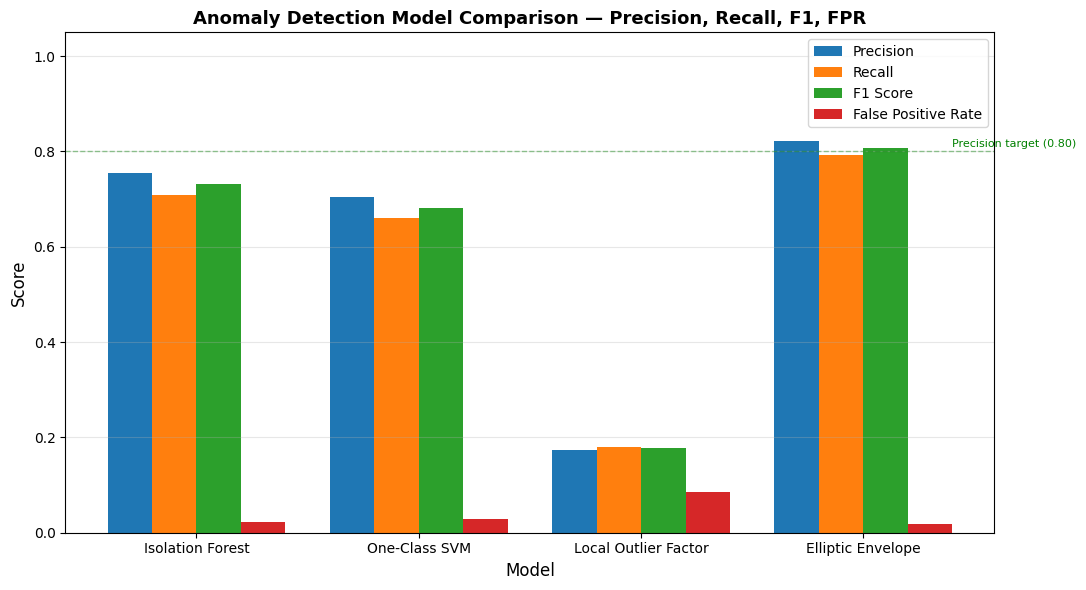


Chart saved to /content/drive/MyDrive/mzazicare-ml/models/model_comparison_chart.png


In [24]:
import matplotlib.pyplot as plt
import numpy as np

metrics = ['precision', 'recall', 'f1_score', 'false_positive_rate']
metric_labels = ['Precision', 'Recall', 'F1 Score', 'False Positive Rate']
models_list = comparison_results['model'].tolist()

x = np.arange(len(models_list))
width = 0.2

fig, ax = plt.subplots(figsize=(11, 6))

for i, (metric, label) in enumerate(zip(metrics, metric_labels)):
    values = comparison_results[metric].values
    bars = ax.bar(x + i * width, values, width, label=label)

ax.set_xlabel('Model', fontsize=12)
ax.set_ylabel('Score', fontsize=12)
ax.set_title('Anomaly Detection Model Comparison — Precision, Recall, F1, FPR', fontsize=13, fontweight='bold')
ax.set_xticks(x + width * 1.5)
ax.set_xticklabels(models_list, fontsize=10)
ax.legend(loc='upper right')
ax.set_ylim(0, 1.05)
ax.grid(axis='y', alpha=0.3)

# Add target reference lines
ax.axhline(y=0.80, color='green', linestyle='--', alpha=0.4, linewidth=1)
ax.text(len(models_list)-0.3, 0.81, 'Precision target (0.80)', fontsize=8, color='green')

plt.tight_layout()
plt.savefig(f'{MODELS}/model_comparison_chart.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"\nChart saved to {MODELS}/model_comparison_chart.png")

15. Detection rate analysis by anomaly type across all models

              Isolation Forest  One-Class SVM  Local Outlier Factor  \
anomaly_type                                                          
combined                 100.0           88.1                  25.4   
device                    82.5           75.4                  10.5   
location                 100.0          100.0                  26.5   
time                      18.2           18.2                  14.3   
velocity                  75.5           69.8                  15.1   

              Elliptic Envelope  
anomaly_type                     
combined                  100.0  
device                    100.0  
location                  100.0  
time                       20.8  
velocity                  100.0  


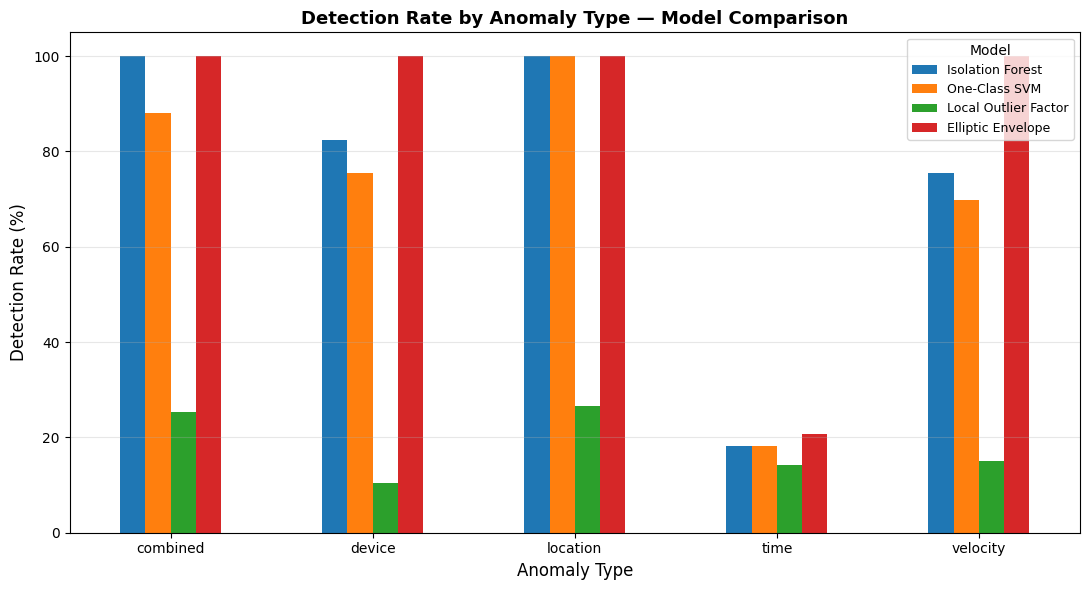


Chart saved to /content/drive/MyDrive/mzazicare-ml/models/detection_by_type_comparison.png


In [25]:
def detection_by_type(name, predictions_raw, meta_test, y_true):
    pred_binary = (predictions_raw == -1).astype(int)
    temp = meta_test.copy()
    temp['true_label'] = y_true
    temp['predicted'] = pred_binary
    anomaly_only = temp[temp['true_label'] == 1]
    breakdown = anomaly_only.groupby('anomaly_type')['predicted'].mean() * 100
    breakdown.name = name
    return breakdown

type_comparison = pd.DataFrame({
    'Isolation Forest': detection_by_type('Isolation Forest', final_model.predict(X_test), meta_test, y_true),
    'One-Class SVM': detection_by_type('One-Class SVM', ocsvm.predict(X_test), meta_test, y_true),
    'Local Outlier Factor': detection_by_type('Local Outlier Factor', lof.predict(X_test), meta_test, y_true),
    'Elliptic Envelope': detection_by_type('Elliptic Envelope', envelope.predict(X_test), meta_test, y_true),
})

print(type_comparison.round(1))

# Visualizing
fig, ax = plt.subplots(figsize=(11, 6))
type_comparison.plot(kind='bar', ax=ax)
ax.set_xlabel('Anomaly Type', fontsize=12)
ax.set_ylabel('Detection Rate (%)', fontsize=12)
ax.set_title('Detection Rate by Anomaly Type — Model Comparison', fontsize=13, fontweight='bold')
ax.legend(title='Model', fontsize=9)
ax.set_ylim(0, 105)
ax.grid(axis='y', alpha=0.3)
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(f'{MODELS}/detection_by_type_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"\nChart saved to {MODELS}/detection_by_type_comparison.png")

16. Saving the model, scaler and metadata

In [26]:
import joblib
import json
from datetime import datetime

# Saving the final model (model_v2, max_features=0.5)
joblib.dump(final_model, f'{MODELS}/isolation_forest_synthetic.pkl')
joblib.dump(scaler, f'{MODELS}/scaler_synthetic.pkl')

metadata = {
    'features': features,
    'contamination': contamination,
    'n_estimators': final_model.n_estimators,
    'max_features': final_model.max_features,
    'trained_on': datetime.now().isoformat(),
    'training_rows': len(X_train),
    'dataset_source': 'synthetic_anomaly_dataset.parquet (RBA baselines + calibrated synthetic injections)',
    'test_metrics': {
        'precision': round(final_precision, 4),
        'recall': round(final_recall, 4),
        'f1_score': round(final_f1, 4),
        'false_positive_rate': round(final_fpr, 4),
    },
    'detection_by_type': type_breakdown.to_dict(orient='records'),
    'detection_by_severity': severity_breakdown.to_dict(orient='records'),
    'model_comparison': comparison_results.to_dict(orient='records'),
    'detection_by_type_all_models': type_comparison.reset_index().to_dict(orient='records'),
    'selection_rationale': (
        'Isolation Forest (max_features=0.5) selected over Elliptic Envelope despite '
        'marginally lower precision/recall, due to: no distributional assumptions required, '
        'better computational scalability for real-time inference, and established use in '
        'prior authentication anomaly detection literature.'
    ),
}

with open(f'{MODELS}/model_metadata_synthetic.json', 'w') as f:
    json.dump(metadata, f, indent=2, default=str)

print("Saved to Google Drive:")
print(f"  {MODELS}/isolation_forest_synthetic.pkl  (model_v2 with max_features=0.5)")
print(f"  {MODELS}/scaler_synthetic.pkl")
print(f"  {MODELS}/model_metadata_synthetic.json")
print(f"  {MODELS}/model_comparison_chart.png")
print(f"  {MODELS}/detection_by_type_comparison.png")

Saved to Google Drive:
  /content/drive/MyDrive/mzazicare-ml/models/isolation_forest_synthetic.pkl  (model_v2 with max_features=0.5)
  /content/drive/MyDrive/mzazicare-ml/models/scaler_synthetic.pkl
  /content/drive/MyDrive/mzazicare-ml/models/model_metadata_synthetic.json
  /content/drive/MyDrive/mzazicare-ml/models/model_comparison_chart.png
  /content/drive/MyDrive/mzazicare-ml/models/detection_by_type_comparison.png
